## Problem Statement

You are working for Accenture as a Data Scientist. Accenture has been commissioned by an insurance company to develop a tool to optimize their marketing efforts. They have given us a data set as a result of an email marketing campaign. The data set includes customer information, described below, as a well as whether the customer responded to the marketing campaign or not.

Design a model that will be able to predict whether a customer will respond to the marketing campaign based on his/her information. In other words, predict the responded target variable described above based on all the input variables provided.

Briefly answer the following questions:

    Describe your model and why did you choose this model over other types of models?
    Describe any other models you have tried and why do you think this model preforms better?
    How did you handle missing data?
    How did you handle categorical (string) data?
    How did you handle unbalanced data?
    How did you handle outliers?
    How did you test your model?


| Type | Variable Name | Description |
| --- | --- | --- |
| **Input Variable** | `custAge` | The age of the customer (in years) |
| **Input Variable** | `profession` | Type of job |
| **Input Variable** | `marital` | Marital status |
| **Input Variable** | `schooling` | Education level |
| **Input Variable** | `default` | Has a previous defaulted account? |
| **Input Variable** | `housing` | Has a housing loan? |
| **Input Variable** | `contact` | Preferred contact type |
| **Input Variable** | `month` | Last contact month |
| **Input Variable** | `day_of_week` | Last contact day of week |
| **Input Variable** | `campaign` | Number of times the customer was contacted during this campaign |
| **Input Variable** | `pdays` | Number of days that passed by after the client was last contacted from a previous campaign (numeric; `999` means client was not previously contacted) |
| **Input Variable** | `previous` | Number of contacts performed before this campaign for this client |
| **Input Variable** | `poutcome` | Outcome of the previous marketing campaign |
| **Input Variable** | `emp.var.rate` | Employment variation rate - quarterly indicator |
| **Input Variable** | `cons.price.idx` | Consumer price index - monthly indicator |
| **Input Variable** | `cons.conf.idx` | Consumer confidence index - monthly indicator |
| **Input Variable** | `euribor3m` | Euribor 3 months rate - daily indicator |
| **Input Variable** | `nr.employed` | Number of employees - quarterly indicator |
| **Input Variable** | `pmonths` | Number of months that passed by after the client was last contacted from a previous campaign (numeric; `999` means client was not previously contacted) |
| **Input Variable** | `pastEmail` | Number of previous emails sent to this user |
| **Target Variable** | `responded` | Did the customer respond to the marketing campaign and purchase a policy? |

In [1]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns
import warnings

from sklearn.model_selection import train_test_split

warnings.filterwarnings('ignore')

## 1. Import data


In [2]:
!pip install openpyxl


[notice] A new release of pip is available: 26.0.1 -> 26.2.1
[notice] To update, run: pip install --upgrade pip


In [3]:
train_df = pd.read_excel('../data/train.xlsx')
test_df = pd.read_excel('../data/test.xlsx')

In [4]:
test_df.head()

,custAge,profession,marital,schooling,default,housing,loan,contact,month,day_of_week,...,previous,poutcome,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed,pmonths,pastEmail,id
0,NaN,admin.,married,NaN,no,no,yes,cellular,sep,wed,...,1,failure,-1.1,94.199,-37.5,0.886,4963.6,999.0,2,1
1,35.0,services,married,high.school,no,no,no,cellular,sep,tue,...,1,success,-3.4,92.379,-29.8,0.788,5017.5,0.1,2,2
2,50.0,blue-collar,married,professional.course,unknown,yes,no,cellular,may,thu,...,1,failure,-1.8,92.893,-46.2,1.327,5099.1,999.0,2,3
3,30.0,admin.,single,university.degree,no,no,no,cellular,aug,wed,...,0,nonexistent,1.4,93.444,-36.1,4.964,5228.1,999.0,0,4
4,39.0,services,divorced,high.school,no,yes,no,cellular,nov,tue,...,0,nonexistent,-0.1,93.200,-42.0,4.153,5195.8,999.0,0,5


In [5]:
train_df.head()

,custAge,profession,marital,schooling,default,housing,loan,contact,month,day_of_week,...,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed,pmonths,pastEmail,responded,profit,id
0,34.0,admin.,single,university.degree,no,no,yes,cellular,apr,wed,...,-1.8,93.075,-47.1,1.498,5099.1,999.0,0.0,no,NaN,1.0
1,31.0,services,single,high.school,no,no,no,cellular,jul,thu,...,1.4,93.918,-42.7,4.968,5228.1,999.0,0.0,no,NaN,2.0
2,NaN,admin.,single,high.school,no,no,no,telephone,jun,NaN,...,1.4,94.465,-41.8,4.961,5228.1,999.0,0.0,no,NaN,3.0
3,52.0,admin.,divorced,university.degree,unknown,yes,no,cellular,jul,tue,...,1.4,93.918,-42.7,4.962,5228.1,999.0,0.0,no,NaN,4.0
4,39.0,blue-collar,single,NaN,unknown,yes,no,cellular,jul,tue,...,1.4,93.918,-42.7,4.961,5228.1,999.0,0.0,no,NaN,5.0


In [6]:
test_df.head()

,custAge,profession,marital,schooling,default,housing,loan,contact,month,day_of_week,...,previous,poutcome,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed,pmonths,pastEmail,id
0,NaN,admin.,married,NaN,no,no,yes,cellular,sep,wed,...,1,failure,-1.1,94.199,-37.5,0.886,4963.6,999.0,2,1
1,35.0,services,married,high.school,no,no,no,cellular,sep,tue,...,1,success,-3.4,92.379,-29.8,0.788,5017.5,0.1,2,2
2,50.0,blue-collar,married,professional.course,unknown,yes,no,cellular,may,thu,...,1,failure,-1.8,92.893,-46.2,1.327,5099.1,999.0,2,3
3,30.0,admin.,single,university.degree,no,no,no,cellular,aug,wed,...,0,nonexistent,1.4,93.444,-36.1,4.964,5228.1,999.0,0,4
4,39.0,services,divorced,high.school,no,yes,no,cellular,nov,tue,...,0,nonexistent,-0.1,93.200,-42.0,4.153,5195.8,999.0,0,5


In [7]:
train_df.tail()


,custAge,profession,marital,schooling,default,housing,loan,contact,month,day_of_week,...,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed,pmonths,pastEmail,responded,profit,id
8235,32.0,self-employed,single,university.degree,no,no,no,cellular,apr,thu,...,-1.8,93.075,-47.1,1.435,5099.1,999.0,0.0,yes,208.000000,8236.0
8236,NaN,housemaid,married,university.degree,no,no,no,cellular,jun,tue,...,-2.9,92.963,-40.8,1.099,5076.2,999.0,0.0,yes,129.000000,8237.0
8237,85.0,housemaid,married,NaN,unknown,yes,no,cellular,apr,tue,...,-1.8,93.749,-34.6,0.642,5008.7,999.0,1.0,yes,33.000000,8238.0
8238,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,172.112069,NaN
8239,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,-87622.112070,NaN


In [8]:
test_df.tail()

,custAge,profession,marital,schooling,default,housing,loan,contact,month,day_of_week,...,previous,poutcome,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed,pmonths,pastEmail,id
32945,NaN,technician,married,professional.course,no,yes,no,telephone,may,NaN,...,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,999.0,0,32946
32946,32.0,blue-collar,married,NaN,no,no,yes,cellular,may,thu,...,0,nonexistent,-1.8,92.893,-46.2,1.266,5099.1,999.0,0,32947
32947,32.0,services,married,high.school,no,no,no,cellular,may,mon,...,0,nonexistent,-1.8,92.893,-46.2,1.299,5099.1,999.0,0,32948
32948,32.0,blue-collar,married,basic.9y,no,yes,no,telephone,jun,wed,...,0,nonexistent,1.4,94.465,-41.8,4.959,5228.1,999.0,0,32949
32949,25.0,admin.,single,university.degree,no,no,no,telephone,jun,mon,...,0,nonexistent,-2.9,92.963,-40.8,1.260,5076.2,999.0,0,32950


In [9]:
test_columns = test_df.columns

In [10]:
train_df.drop(columns=test_columns)

,responded,profit
0,no,NaN
1,no,NaN
2,no,NaN
3,no,NaN
4,no,NaN
...,...,...
8235,yes,208.000000
8236,yes,129.000000
8237,yes,33.000000
8238,NaN,172.112069


Since the problem staement is a classification problem.'Responded' is our target variable. We will drop 'profit' from training data.
We will remove the indentifier columns to prevent data leakage too.

In [11]:
train_df.drop(columns=['profit','id'], inplace=True)

In [12]:
train_df.drop(train_df.tail(2).index, inplace=True)

In [13]:
train_df.columns

Index(['custAge', 'profession', 'marital', 'schooling', 'default', 'housing',
       'loan', 'contact', 'month', 'day_of_week', 'campaign', 'pdays',
       'previous', 'poutcome', 'emp.var.rate', 'cons.price.idx',
       'cons.conf.idx', 'euribor3m', 'nr.employed', 'pmonths', 'pastEmail',
       'responded'],
      dtype='object')

In [14]:
print("Number of Training rows:",train_df.shape[0])
print("Number of Training columns:",train_df.shape[1])

print("Number of Test rows:",test_df.shape[0])
print("Number of Test columns:",test_df.shape[1])

Number of Training rows: 8238
Number of Training columns: 22
Number of Test rows: 32950
Number of Test columns: 22


In [15]:
train_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8238 entries, 0 to 8237
Data columns (total 22 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   custAge         6224 non-null   float64
 1   profession      8238 non-null   object 
 2   marital         8238 non-null   object 
 3   schooling       5832 non-null   object 
 4   default         8238 non-null   object 
 5   housing         8238 non-null   object 
 6   loan            8238 non-null   object 
 7   contact         8238 non-null   object 
 8   month           8238 non-null   object 
 9   day_of_week     7451 non-null   object 
 10  campaign        8238 non-null   float64
 11  pdays           8238 non-null   float64
 12  previous        8238 non-null   float64
 13  poutcome        8238 non-null   object 
 14  emp.var.rate    8238 non-null   float64
 15  cons.price.idx  8238 non-null   float64
 16  cons.conf.idx   8238 non-null   float64
 17  euribor3m       8238 non-null   f

In [16]:
train_df.describe()

,custAge,campaign,pdays,previous,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed,pmonths,pastEmail
count,6224.000000,8238.000000,8238.000000,8238.000000,8238.000000,8238.000000,8238.000000,8238.000000,8238.000000,8238.000000,8238.000000
mean,39.953728,2.531682,960.916606,0.183054,0.056397,93.570977,-40.577907,3.586929,5165.575965,960.687436,0.365501
std,10.540516,2.709773,190.695054,0.514209,1.566550,0.578782,4.650101,1.742784,72.727423,191.841012,1.294101
min,18.000000,1.000000,0.000000,0.000000,-3.400000,92.201000,-50.800000,0.634000,4963.600000,0.000000,0.000000
25%,32.000000,1.000000,999.000000,0.000000,-1.800000,93.075000,-42.700000,1.334000,5099.100000,999.000000,0.000000
50%,38.000000,2.000000,999.000000,0.000000,1.100000,93.444000,-41.800000,4.857000,5191.000000,999.000000,0.000000
75%,47.000000,3.000000,999.000000,0.000000,1.400000,93.994000,-36.400000,4.961000,5228.100000,999.000000,0.000000
max,94.000000,40.000000,999.000000,6.000000,1.400000,94.767000,-26.900000,5.045000,5228.100000,999.000000,25.000000


In [17]:
train_df.isna().sum()

custAge           2014
profession           0
marital              0
schooling         2406
default              0
housing              0
loan                 0
contact              0
month                0
day_of_week        787
campaign             0
pdays                0
previous             0
poutcome             0
emp.var.rate         0
cons.price.idx       0
cons.conf.idx        0
euribor3m            0
nr.employed          0
pmonths              0
pastEmail            0
responded            0
dtype: int64

In [18]:
test_df.isna().sum()

custAge           8042
profession           0
marital              0
schooling         9770
default              0
housing              0
loan                 0
contact              0
month                0
day_of_week       3328
campaign             0
pdays                0
previous             0
poutcome             0
emp.var.rate         0
cons.price.idx       0
cons.conf.idx        0
euribor3m            0
nr.employed          0
pmonths              0
pastEmail            0
id                   0
dtype: int64

## 2.EDA

#### 2.1 Target analysis

In [19]:
target =train_df['responded']

In [20]:
target.value_counts()

responded
no     7310
yes     928
Name: count, dtype: int64

In [21]:
target.value_counts(normalize=True)

responded
no     0.887351
yes    0.112649
Name: proportion, dtype: float64

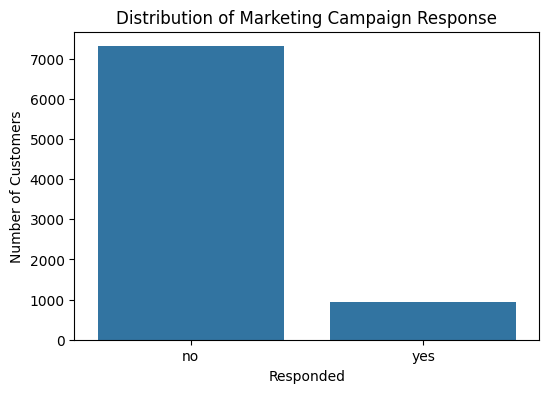

In [22]:
plt.figure(figsize =(6,4))
sns.countplot(
    data = train_df.drop(columns = 'responded'),
    x = train_df['responded']
)

plt.title("Distribution of Marketing Campaign Response")
plt.xlabel("Responded")
plt.ylabel("Number of Customers")

plt.show()

*The is class imbalance present in the target variable*. Out of all the people reached, only 11.26~ percent people responded. 
This might motivate us to use a ensemble learning method since they handle unbalance data.

### 2.2 train and test datatype summary

In [23]:
dtype_test_summary = pd.DataFrame({
    "dtype": test_df.dtypes,
    "missing": test_df.isna().sum(),
    "unique_values": test_df.nunique()
})

dtype_test_summary

,dtype,missing,unique_values
custAge,float64,8042,75
profession,object,0,12
marital,object,0,4
schooling,object,9770,8
default,object,0,3
housing,object,0,3
loan,object,0,3
contact,object,0,2
month,object,0,10
day_of_week,object,3328,5


In [24]:
dtype_train_summary = pd.DataFrame({
    "dtype": train_df.dtypes,
    "missing": train_df.isna().sum(),
    "unique_values": train_df.nunique()
})

dtype_train_summary

,dtype,missing,unique_values
custAge,float64,2014,72
profession,object,0,12
marital,object,0,4
schooling,object,2406,8
default,object,0,3
housing,object,0,3
loan,object,0,3
contact,object,0,2
month,object,0,10
day_of_week,object,787,5


### 2.3 duplicate analysis

In [25]:
duplicated_count = train_df.duplicated().sum()

print("Duplicated rows:", duplicated_count)

Duplicated rows: 36


In [26]:
train_df[train_df.duplicated(keep = False)].sort_values(by='custAge')

,custAge,profession,marital,schooling,default,housing,loan,contact,month,day_of_week,...,previous,poutcome,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed,pmonths,pastEmail,responded
3447,25.0,admin.,single,high.school,no,no,no,cellular,jul,wed,...,0.0,nonexistent,1.4,93.918,-42.7,4.963,5228.1,999.0,0.0,no
3191,25.0,admin.,single,high.school,no,no,no,cellular,jul,wed,...,0.0,nonexistent,1.4,93.918,-42.7,4.963,5228.1,999.0,0.0,no
6152,27.0,admin.,single,university.degree,unknown,yes,no,cellular,jul,tue,...,0.0,nonexistent,1.4,93.918,-42.7,4.961,5228.1,999.0,0.0,no
2291,27.0,admin.,single,university.degree,unknown,yes,no,cellular,jul,tue,...,0.0,nonexistent,1.4,93.918,-42.7,4.961,5228.1,999.0,0.0,no
3497,28.0,blue-collar,single,NaN,no,no,no,cellular,jul,fri,...,0.0,nonexistent,1.4,93.918,-42.7,4.962,5228.1,999.0,0.0,no
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
5882,NaN,admin.,married,NaN,no,no,no,cellular,jul,fri,...,0.0,nonexistent,1.4,93.918,-42.7,4.963,5228.1,999.0,0.0,no
5909,NaN,admin.,single,university.degree,no,no,no,cellular,aug,wed,...,0.0,nonexistent,1.4,93.444,-36.1,4.964,5228.1,999.0,0.0,no
6134,NaN,technician,married,NaN,no,yes,no,telephone,may,fri,...,0.0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,999.0,0.0,no
6483,NaN,retired,married,basic.4y,unknown,yes,no,telephone,may,NaN,...,0.0,nonexistent,1.1,93.994,-36.4,4.858,5191.0,999.0,0.0,no


Observation:

- There are 36 dpulicate rows. We will remove them in feature engineering


### 2.4 Missing Value analysis

In [27]:
null_columns = ['schooling','custAge','day_of_week']

In [28]:
missing_summary = (
    train_df.isna()
    .sum()
    .to_frame("missing_count")
)

missing_summary["missing_percent"] = (
    missing_summary["missing_count"] / len(train_df) * 100
)

missing_summary = missing_summary.sort_values(
    "missing_percent",
    ascending=False
)

missing_summary

,missing_count,missing_percent
schooling,2406,29.206118
custAge,2014,24.447681
day_of_week,787,9.553290
previous,0,0.000000
pastEmail,0,0.000000
pmonths,0,0.000000
nr.employed,0,0.000000
euribor3m,0,0.000000
cons.conf.idx,0,0.000000
cons.price.idx,0,0.000000


- 'Missing values': custAge, schooling and days_of_week contain missing values in both test and train.

Cannot drop the null rows due to their large number.
Nulls a are represented as Nan. Ensemble models handle missing values natively. BUt we can use a custom function for baseline algorithms. The custo function will implement forard fill.

### 2.5 Categorical And Numerical analysis

In [29]:
categorical_data = train_df.select_dtypes(exclude=['number'])
numerical_data = train_df.select_dtypes(include=['number'])

categorical_data.drop(columns='responded', inplace=True)

### 2.1 Categorical Bivariate analysis

In [30]:
categorical_features = categorical_data.columns.tolist()

for col in categorical_features:
    temp = train_df.copy()
    temp[col] = temp[col].fillna("Missing")

    response_rate = (
        pd.crosstab(
            temp[col],
            temp["responded"],
            normalize="index"
        )["yes"] * 100
    ).sort_values(ascending=False)

    print(f"\n--- {col} ---")
    print(response_rate.round(2))


--- profession ---
profession
student          35.22
retired          23.44
unemployed       14.74
admin.           12.84
unknown          12.68
self-employed    12.19
management       11.15
technician        9.84
entrepreneur      9.24
blue-collar       8.07
housemaid         7.98
services          7.45
Name: yes, dtype: float64

--- marital ---
marital
unknown     20.00
single      13.89
married     10.25
divorced     9.98
Name: yes, dtype: float64

--- schooling ---
schooling
unknown                16.54
university.degree      13.34
Missing                11.47
professional.course    10.98
high.school            10.67
basic.4y                9.56
basic.6y                9.27
basic.9y                8.00
illiterate              0.00
Name: yes, dtype: float64

--- default ---
default
no         12.71
unknown     5.38
yes         0.00
Name: yes, dtype: float64

--- housing ---
housing
unknown    13.59
yes        11.58
no         10.79
Name: yes, dtype: float64

--- loan ---
loan
unkno

In [31]:
selected_cat = [
    "profession",
    "schooling",
    "contact",
    "month",
    "poutcome"
]

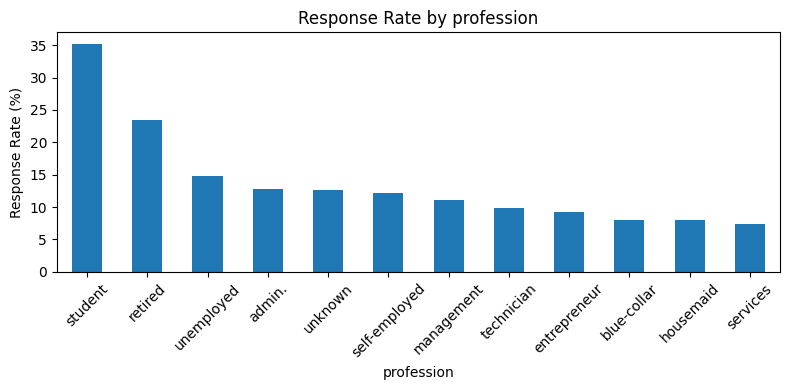

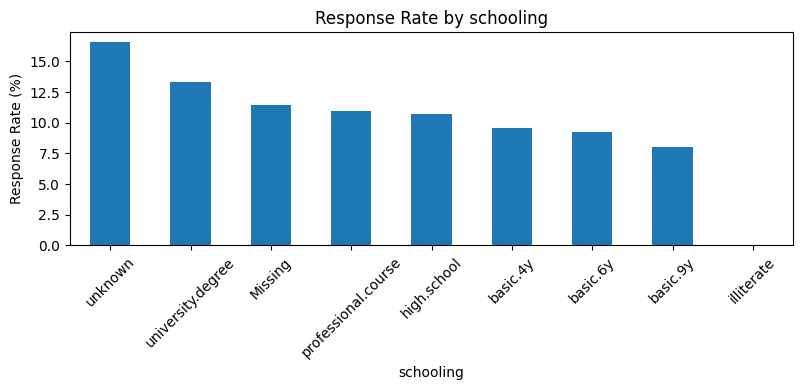

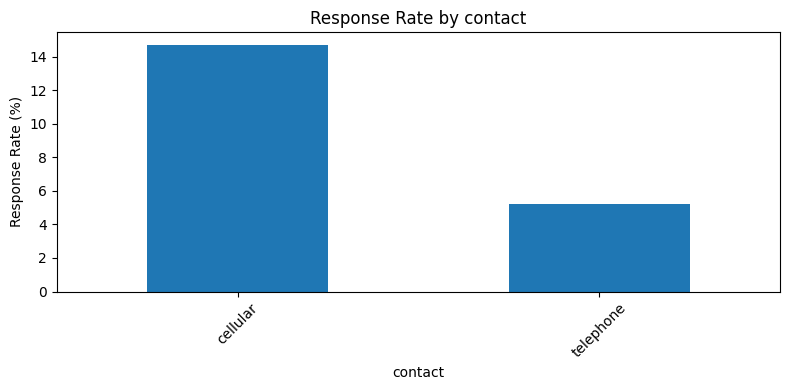

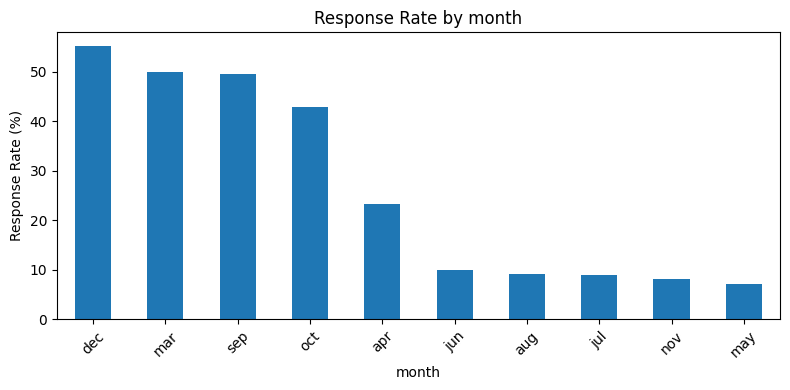

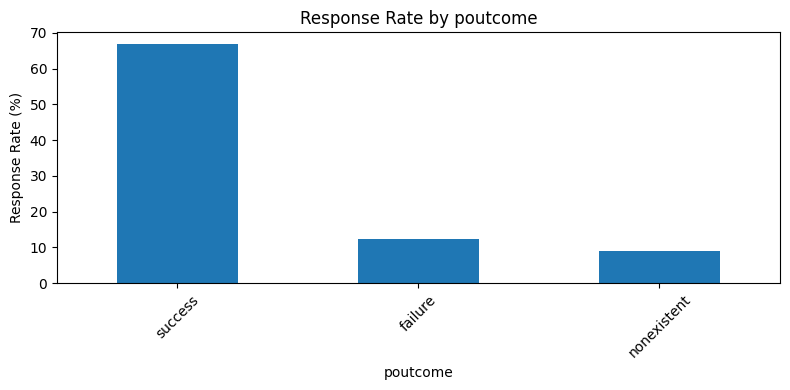

In [32]:
for col in selected_cat:
    temp = train_df.copy()
    temp[col] = temp[col].fillna("Missing")

    response_rate = (
        pd.crosstab(
            temp[col],
            temp["responded"],
            normalize="index"
        )["yes"] * 100
    ).sort_values(ascending=False)

    plt.figure(figsize=(8, 4))
    response_rate.plot(kind="bar")
    plt.title(f"Response Rate by {col}")
    plt.ylabel("Response Rate (%)")
    plt.xlabel(col)
    plt.xticks(rotation=45)
    plt.tight_layout()
    plt.show()

### 2.5.2 Numerical Bivariate analysis

In [33]:
train_df.groupby("responded")[numerical_data.columns].mean().T

responded,no,yes
custAge,39.840852,40.870968
campaign,2.590834,2.065733
pdays,983.920793,779.709052
previous,0.143639,0.493534
emp.var.rate,0.225472,-1.275431
cons.price.idx,93.598417,93.354830
cons.conf.idx,-40.639083,-40.096013
euribor3m,3.782107,2.049483
nr.employed,5174.874884,5092.326940
pmonths,983.833516,778.362177


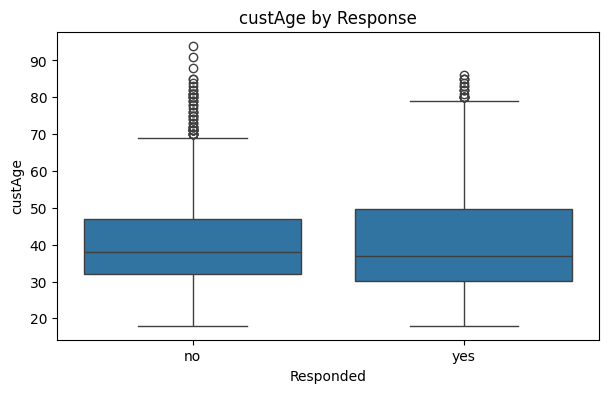

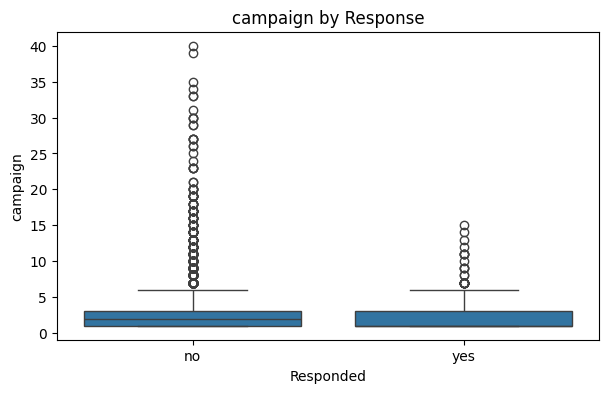

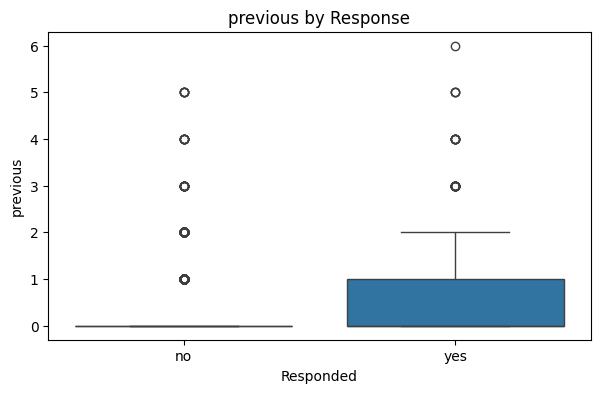

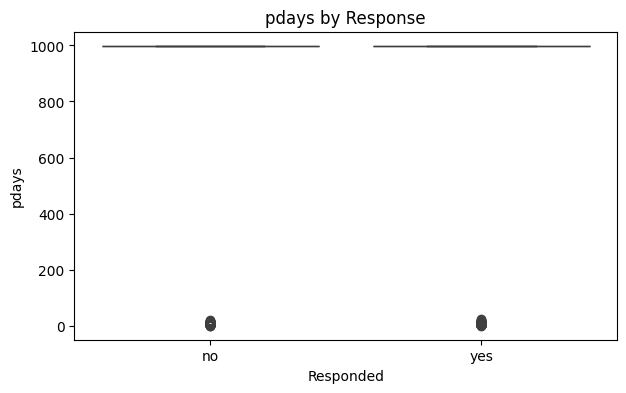

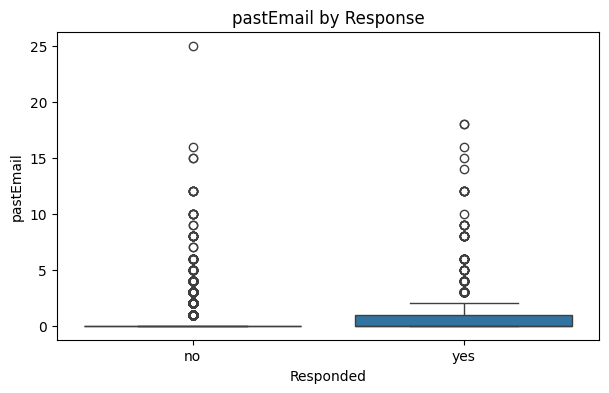

In [34]:
selected_num = [
    "custAge",
    "campaign",
    "previous",
    "pdays",
    "pastEmail"
]

for col in selected_num:
    plt.figure(figsize=(7, 4))

    sns.boxplot(
        data=train_df,
        x="responded",
        y=col
    )

    plt.title(f"{col} by Response")
    plt.xlabel("Responded")
    plt.ylabel(col)

    plt.show()

### 2.6 Outlier Detection 

In [35]:
#Check Skewnes
skewness = numerical_data.skew().sort_values(ascending=False)

skewness

pastEmail         6.055047
campaign          4.823943
previous          3.834599
custAge           0.866271
cons.conf.idx     0.293467
cons.price.idx   -0.185409
euribor3m        -0.662148
emp.var.rate     -0.675174
nr.employed      -1.019491
pmonths          -4.808111
pdays            -4.808238
dtype: float64

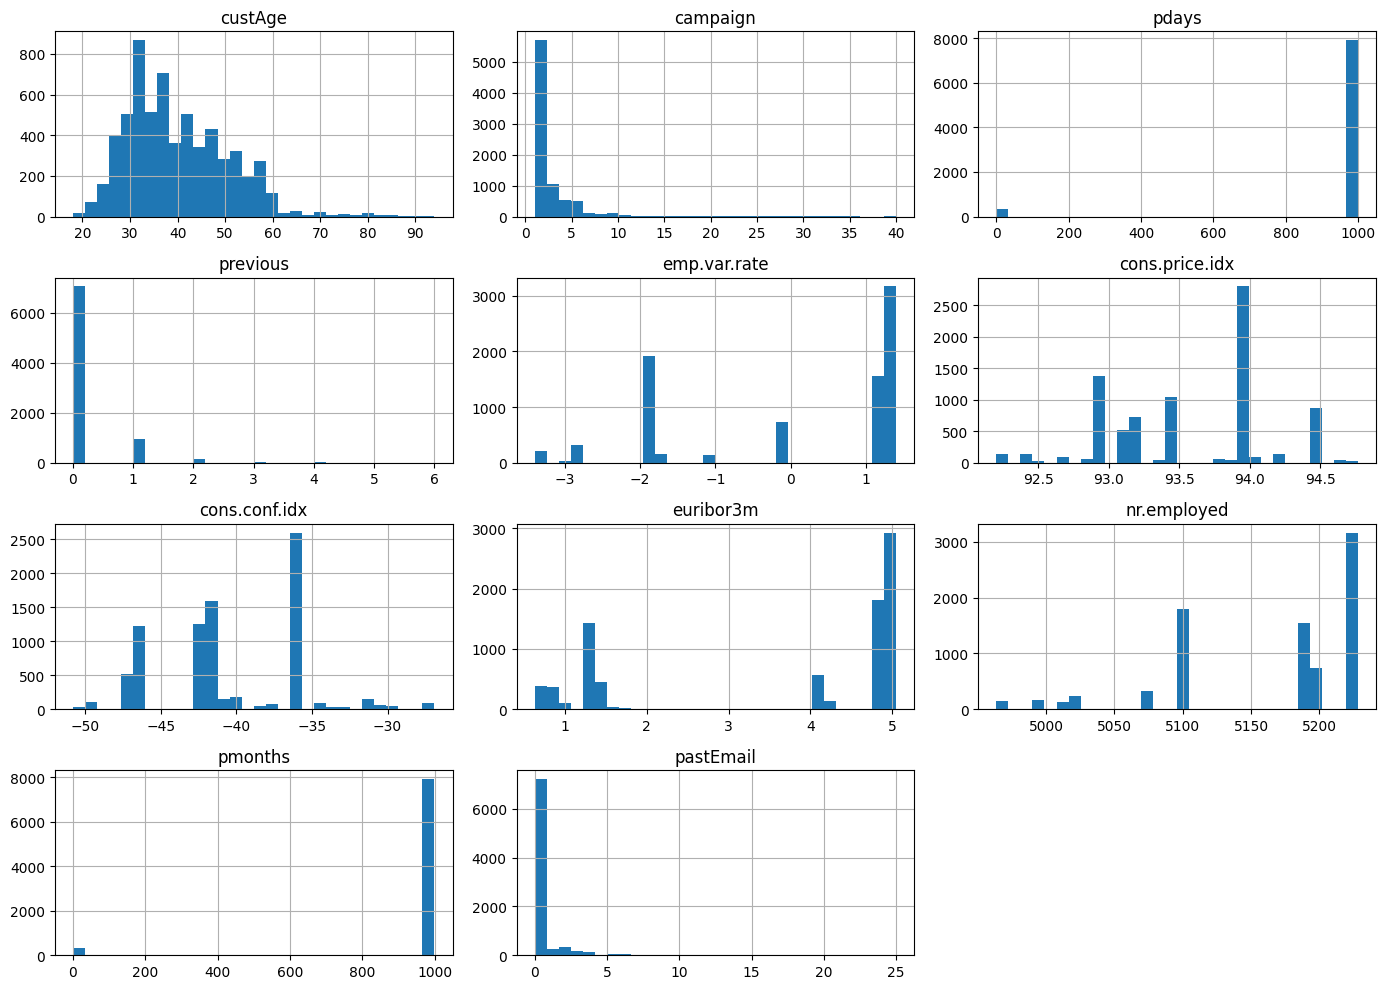

In [36]:
numerical_data.hist(
    figsize=(14, 10),
    bins=30
)

plt.tight_layout()
plt.show()

Since there is high skeness in the the data we would use IQR instead of Z-score method to deal with outliers

In [37]:
train_df['pdays'].value_counts()

pdays
999.0    7922
6.0        90
3.0        86
4.0        25
9.0        17
7.0        16
2.0        13
12.0       12
10.0        8
5.0         7
13.0        6
14.0        6
15.0        5
11.0        5
16.0        4
1.0         4
0.0         3
8.0         3
17.0        2
19.0        1
25.0        1
21.0        1
22.0        1
Name: count, dtype: int64

In [38]:
train_df['pmonths'].value_counts()

pmonths
999.000000    7922
0.200000        90
0.100000        86
0.133333        25
0.300000        17
0.233333        16
0.066667        13
0.400000        12
0.333333         8
0.166667         7
0.433333         6
0.466667         6
0.500000         5
0.366667         5
0.533333         4
0.033333         4
0.000000         3
0.266667         3
0.566667         2
0.633333         1
0.833333         1
0.700000         1
0.733333         1
Name: count, dtype: int64

We have to check skew without 999, which is used to indicate users who have not been reached.

In [39]:
skew_without_999 = numerical_data.copy()

skew_without_999["pdays"] = skew_without_999["pdays"].replace(999, np.nan)
skew_without_999["pmonths"] = skew_without_999["pmonths"].replace(999, np.nan)

skew_without_999.skew().sort_values(ascending=False)

pastEmail         6.055047
campaign          4.823943
previous          3.834599
pmonths           1.517232
pdays             1.517232
custAge           0.866271
cons.conf.idx     0.293467
cons.price.idx   -0.185409
euribor3m        -0.662148
emp.var.rate     -0.675174
nr.employed      -1.019491
dtype: float64

| Skewness | Interpretation |
|---:|---|
| -0.5 to 0.5 | Approximately symmetric |
| 0.5 to 1 | Moderately skewed |
| > 1 | Highly right-skewed |
| -1 to -0.5 | Moderately left-skewed |
| < -1 | Highly left-skewed |

Skewnes of pdays and pmonths goes from Highlt left skewed to Highly right skews 

In [40]:
outlier_summary = []

for col in numerical_data.columns:
    Q1 = train_df[col].quantile(0.25)
    Q3 = train_df[col].quantile(0.75)

    IQR = Q3 - Q1

    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR

    outlier_count = (
        (train_df[col] < lower) |
        (train_df[col] > upper)
    ).sum()

    outlier_summary.append({
        "feature": col,
        "IQR" : IQR,
        "outlier_count": outlier_count,
        "outlier_percent": outlier_count / len(train_df) * 100
    })

outlier_summary = pd.DataFrame(outlier_summary)

outlier_summary.sort_values(
    "outlier_percent",
    ascending=False
)

,feature,IQR,outlier_count,outlier_percent
3,previous,0.000,1178,14.299587
10,pastEmail,0.000,1019,12.369507
1,campaign,2.000,460,5.583880
2,pdays,0.000,316,3.835882
9,pmonths,0.000,316,3.835882
6,cons.conf.idx,6.300,95,1.153193
0,custAge,15.000,86,1.043943
4,emp.var.rate,3.200,0,0.000000
5,cons.price.idx,0.919,0,0.000000
7,euribor3m,3.627,0,0.000000


In [41]:
print("pdays = 999:")
print(train_df["pdays"].value_counts().head())

print("\npmonths = 999:")
print(train_df["pmonths"].value_counts().head())

pdays = 999:
pdays
999.0    7922
6.0        90
3.0        86
4.0        25
9.0        17
Name: count, dtype: int64

pmonths = 999:
pmonths
999.000000    7922
0.200000        90
0.100000        86
0.133333        25
0.300000        17
Name: count, dtype: int64


## 3. Modelling Split
We will split train.xlsx to 80% Training and 20% Validation data. Test.xlsx will be used for unseen data testing.

In [42]:
train_df.head()

,custAge,profession,marital,schooling,default,housing,loan,contact,month,day_of_week,...,previous,poutcome,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed,pmonths,pastEmail,responded
0,34.0,admin.,single,university.degree,no,no,yes,cellular,apr,wed,...,0.0,nonexistent,-1.8,93.075,-47.1,1.498,5099.1,999.0,0.0,no
1,31.0,services,single,high.school,no,no,no,cellular,jul,thu,...,0.0,nonexistent,1.4,93.918,-42.7,4.968,5228.1,999.0,0.0,no
2,NaN,admin.,single,high.school,no,no,no,telephone,jun,NaN,...,0.0,nonexistent,1.4,94.465,-41.8,4.961,5228.1,999.0,0.0,no
3,52.0,admin.,divorced,university.degree,unknown,yes,no,cellular,jul,tue,...,0.0,nonexistent,1.4,93.918,-42.7,4.962,5228.1,999.0,0.0,no
4,39.0,blue-collar,single,NaN,unknown,yes,no,cellular,jul,tue,...,0.0,nonexistent,1.4,93.918,-42.7,4.961,5228.1,999.0,0.0,no


In [43]:
X = train_df.drop(columns ='responded')
y = train_df['responded'].map({"yes":1, "no":0})

In [44]:
X_train, X_val,y_train, y_val = train_test_split(X,y,test_size= 0.2, stratify = y, random_state = 42) 

## 4. Feature Engineering

In [45]:
def engineer_features(df):
    df = df.copy()

    # Previous contact indicator
    df["previously_contacted"] = (df["pdays"] != 999).astype(int)

    # Convert sentinel values to missing
    df["pdays"] = df["pdays"].replace(999, np.nan)
    df["pmonths"] = df["pmonths"].replace(999, np.nan)

    return df

In [46]:
X_train = engineer_features(X_train)
X_val = engineer_features(X_val)

X_test_fe = feature_engineering(X_test) # later

## 5. Model Specific Preprocessing 

| | Logistic Regression | Random Forest | LightGBM |
|-|-|-|-|
| Imputation | Yes | Yes | Native missing handling |
| One-hot encoding | Yes | Yes | No |
| Scaling | Yes | No | No |
| Native categorical | No | No | **Yes** |

In [47]:
numeric_cols = X_train.select_dtypes(include="number").columns.tolist()
categorical_cols = X_train.select_dtypes(include="object").columns.tolist()
print("Numerical:", numeric_cols)
print("Categorical:", categorical_cols)

Numerical: ['custAge', 'campaign', 'pdays', 'previous', 'emp.var.rate', 'cons.price.idx', 'cons.conf.idx', 'euribor3m', 'nr.employed', 'pmonths', 'pastEmail', 'previously_contacted']
Categorical: ['profession', 'marital', 'schooling', 'default', 'housing', 'loan', 'contact', 'month', 'day_of_week', 'poutcome']


### 5.1 Logistic regression

Logistic Regression expects numerical inputs, so we need to:
1. Impute missing numerical values
2. Impute missing categorical values
3. One-hot encode categorical variables
4. Scale numerical variables

In [92]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
import lightgbm as lgb
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    confusion_matrix,
    ConfusionMatrixDisplay,
    classification_report
)


In [ ]:
numeric_transformer = Pipeline([
    ("imputer", SimpleImputer(strategy="mean")),
    ("scaler",StandardScaler())
    ])

categorical_transformer = Pipeline([
    ("imputer", SimpleImputer(strategy = "most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown='ignore'))
])

lr_preprocessor = ColumnTransformer([
    ("num",numeric_transformer, numeric_cols),
    ("cat", categorical_transformer,categorical_cols)
])

lr_model = Pipeline([
    ("preprocessor", lr_preprocessor),
    ("classifier", LogisticRegression( class_weight="balanced"))
])

In [ ]:
lr_model.fit(X_train, y_train)

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer()),
                                                                  ('scaler',
                                                                   StandardScaler())]),
                                                  ['custAge', 'campaign',
                                                   'pdays', 'previous',
                                                   'emp.var.rate',
                                                   'cons.price.idx',
                                                   'cons.conf.idx', 'euribor3m',
                                                   'nr.employed', 'pmonths',
                                                   'pastEmail',
                                                   'previously_contacted']),
                                                 ('cat',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='most_frequent')),
                                                                  ('onehot',
                                                                   OneHotEncoder(handle_unknown='ignore'))]),
                                                  ['profession', 'marital',
                                                   'schooling', 'default',
                                                   'housing', 'loan', 'contact',
                                                   'month', 'day_of_week',
                                                   'poutcome'])])),
                ('classifier',
                 LogisticRegression(class_weight='balanced', max_iter=1000))])

### 5.2 Random Forest
1. Impute missing categorical values
2. Impute missing numerical values
3. One-hot encode categorical values

In [ ]:
rf_numeric_transformer = Pipeline([
    ("imputer", SimpleImputer(strategy="median"))
])

rf_categorical_transformer = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore"))
])

rf_preprocessor = ColumnTransformer([
    ("num",rf_numeric_transformer, numeric_cols),
    ("cat",rf_categorical_transformer,categorical_cols)
])

rf_model = Pipeline([
    ("preprocessor", rf_preprocessor),
    ("classifier",RandomForestClassifier(n_estimators=500,
        random_state=42,
        n_jobs=-1, class_weight="balanced"))
])

In [ ]:
rf_model.fit(X_train, y_train)

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='median'))]),
                                                  ['custAge', 'campaign',
                                                   'pdays', 'previous',
                                                   'emp.var.rate',
                                                   'cons.price.idx',
                                                   'cons.conf.idx', 'euribor3m',
                                                   'nr.employed', 'pmonths',
                                                   'pastEmail',
                                                   'previously_contacted']),
                                                 ('cat',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='most_frequent')),
                                                                  ('onehot',
                                                                   OneHotEncoder(handle_unknown='ignore'))]),
                                                  ['profession', 'marital',
                                                   'schooling', 'default',
                                                   'housing', 'loan', 'contact',
                                                   'month', 'day_of_week',
                                                   'poutcome'])])),
                ('classifier',
                 RandomForestClassifier(class_weight='balanced',
                                        n_estimators=500, n_jobs=-1,
                                        random_state=42))])

### 5.3 LightGBM
LightGBM can work with:
- missing numerical values
- categorical variables
- nonlinear relationships
So we don't need the same preprocessing pipeline.
We're going to let LightGBM use its native categorical handling.

In [ ]:
X_train_lgb = X_train.copy()
X_val_lgb = X_val.copy()

for col in categorical_cols:
    X_train_lgb[col] = X_train_lgb[col].astype("category")
    X_val_lgb[col] = X_val_lgb[col].astype("category")

for col in categorical_cols:
    X_train_lgb[col] = X_train_lgb[col].cat.add_categories(["Missing"])
    X_val_lgb[col] = X_val_lgb[col].cat.add_categories(["Missing"])

    X_train_lgb[col] = X_train_lgb[col].fillna("Missing")
    X_val_lgb[col] = X_val_lgb[col].fillna("Missing")

In [ ]:
lgb_model = lgb.LGBMClassifier(
    n_estimators=300,
    learning_rate=0.05,
    num_leaves=30,
    random_state=42,
    verbosity=-1,
    is_unbalance = True
)

In [ ]:
lgb_model.fit(
    X_train_lgb,
    y_train,
    categorical_feature=categorical_cols
)

LGBMClassifier(is_unbalance=True, learning_rate=0.05, n_estimators=300,
               num_leaves=30, random_state=42, verbosity=-1)

## 6. Model evaluation

In [ ]:

def evaluate_model(name, model, X_valid, y_valid):

    # Generate class predictions and response probabilities
    y_pred = model.predict(X_valid)
    y_prob = model.predict_proba(X_valid)[:, 1]

    # Calculate metrics
    metrics = {
        "Model": name,
        "Accuracy": accuracy_score(y_valid, y_pred),
        "Precision": precision_score(
            y_valid, y_pred, zero_division=0
        ),
        "Recall": recall_score(
            y_valid, y_pred, zero_division=0
        ),
        "F1-score": f1_score(
            y_valid, y_pred, zero_division=0
        ),
        "ROC-AUC": roc_auc_score(y_valid, y_prob),
        "Average Precision": average_precision_score(
            y_valid, y_prob
        )
    }

    # Display classification report
    print(f"\n{'=' * 50}")
    print(f"{name} — Evaluation")
    print("=" * 50)

    print("\nClassification Report:")
    print(classification_report(
        y_valid,
        y_pred,
        labels=[0, 1],
        target_names=["No Response", "Responded"],
        zero_division=0
    ))

    # Calculate confusion matrix in a fixed label order
    cm = confusion_matrix(
        y_valid,
        y_pred,
        labels=[0, 1]
    )

    # Visualise the confusion matrix
    display = ConfusionMatrixDisplay(
        confusion_matrix=cm,
        display_labels=["No Response", "Responded"]
    )

    fig, ax = plt.subplots(figsize=(6, 5))

    display.plot(
        ax=ax,
        cmap="Blues",
        values_format="d",
        colorbar=False
    )

    ax.set_title(f"{name} — Confusion Matrix")
    ax.set_xlabel("Predicted Label")
    ax.set_ylabel("Actual Label")

    plt.tight_layout()
    plt.show()

    return metrics



Logistic Regression — Evaluation

Classification Report:
              precision    recall  f1-score   support

 No Response       0.95      0.86      0.90      1462
   Responded       0.37      0.66      0.48       186

    accuracy                           0.84      1648
   macro avg       0.66      0.76      0.69      1648
weighted avg       0.89      0.84      0.85      1648



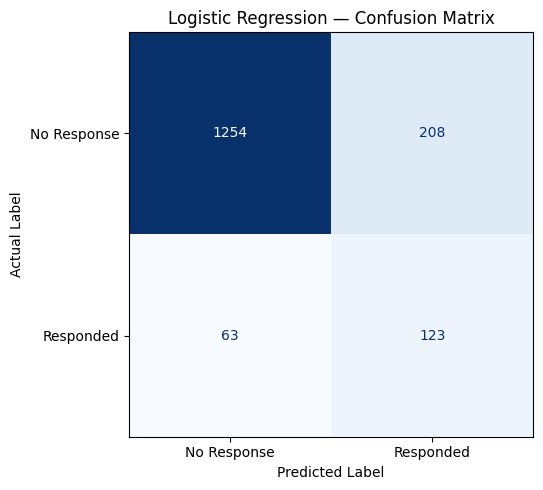

In [ ]:
lr_metrics = evaluate_model(
    "Logistic Regression",
    lr_model,
    X_val,
    y_val
)



Random Forest — Evaluation

Classification Report:
              precision    recall  f1-score   support

 No Response       0.91      0.98      0.94      1462
   Responded       0.57      0.24      0.34       186

    accuracy                           0.89      1648
   macro avg       0.74      0.61      0.64      1648
weighted avg       0.87      0.89      0.87      1648



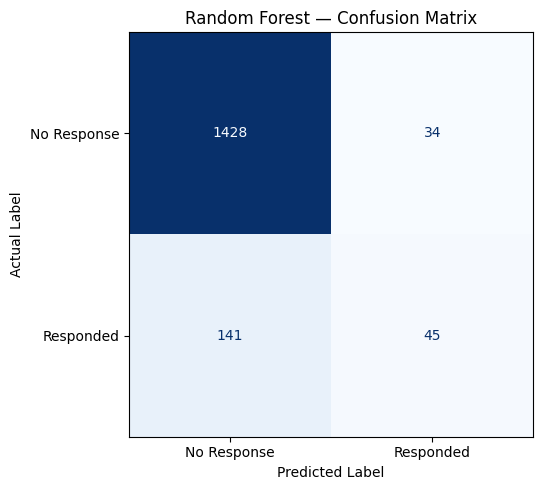

In [ ]:

rf_metrics = evaluate_model(
    "Random Forest",
    rf_model,
    X_val,
    y_val
)



LightGBM — Evaluation

Classification Report:
              precision    recall  f1-score   support

 No Response       0.94      0.90      0.92      1462
   Responded       0.42      0.57      0.49       186

    accuracy                           0.86      1648
   macro avg       0.68      0.74      0.70      1648
weighted avg       0.88      0.86      0.87      1648



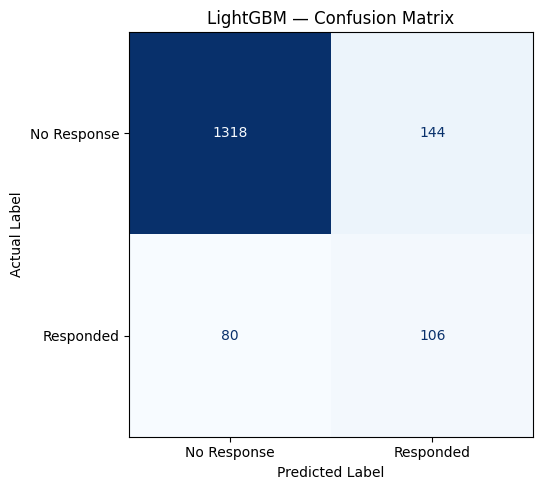

In [ ]:

lgb_metrics = evaluate_model("LightGBM",lgb_model,X_val_lgb,y_val)

## 7. Model Comparison

In [ ]:
results = pd.DataFrame([
    lr_metrics,
    rf_metrics,
    lgb_metrics
])

results = results.set_index("Model")

results.round(4)

,Accuracy,Precision,Recall,F1-score,ROC-AUC,Average Precision
Model,,,,,,
Logistic Regression,0.8356,0.3716,0.6613,0.4758,0.8135,0.4965
Random Forest,0.8938,0.5696,0.2419,0.3396,0.7962,0.4190
LightGBM,0.8641,0.4240,0.5699,0.4862,0.7973,0.4706


In [ ]:
# rank models by metrics
metrics_to_compare = ['Accuracy',	'Precision'	,'Recall'	,'F1-score','ROC-AUC',	'Average Precision']

In [ ]:
rankings = comparison[metrics_to_compare].rank(
    ascending = False,
    method = "min"
)

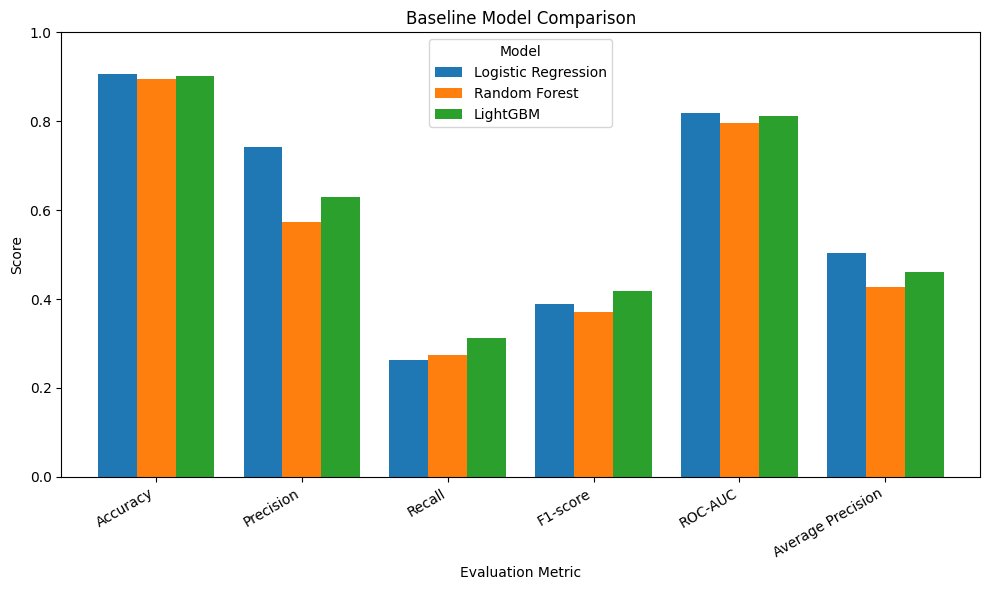

In [ ]:
comparison[metrics_to_compare].T.plot(
    kind ="bar", figsize = (10,6), width = 0.8
)

plt.title("Baseline Model Comparison")
plt.xlabel("Evaluation Metric")
plt.ylabel("Score")
plt.xticks(rotation=30, ha="right")
plt.ylim(0, 1)
plt.legend(title="Model")
plt.tight_layout()
plt.show()

- Logistic Regression: highest ROC-AUC (0.8135) and Average Precision (0.4965).
- Random Forest: highest accuracy (0.8938), but the lowest recall and F1-score.
- Balanced LightGBM: highest recall (0.5699) and F1-score (0.4862).

## 8. Hyper parameters tuning
We will test class balancing on our two stronges candidiates:
1. Logisitic Regression
2. LightGBM

In [187]:
from sklearn.model_selection import (
    GridSearchCV,
    RandomizedSearchCV,
    StratifiedKFold
)
from sklearn.base import clone
from scipy.stats import randint, loguniform, uniform
import lightgbm as lgb

In [188]:
# Shared CV folds for a fair comparison
cv_strategy = StratifiedKFold(
    n_splits=3,
    shuffle=True,
    random_state=42
)

# Parameter grid
lr_param_grid = {
    "classifier__C": [0.01, 0.1, 1, 10],
    "classifier__penalty": ["l1", "l2"],
    "classifier__solver": ["liblinear"]
}

# Balanced Logistic Regression pipeline
lr_search_model = clone(lr_model).set_params(
    classifier__class_weight="balanced"
)

# Grid search initialisation
lr_grid = GridSearchCV(
    estimator=lr_search_model,
    param_grid=lr_param_grid,
    scoring="f1",
    cv=cv_strategy,
    n_jobs=-1,
    verbose=1,
    refit=True
)

In [189]:
# Parameter distributions
lgb_param_distributions = {
    "n_estimators": randint(200, 701),
    "learning_rate": loguniform(0.01, 0.15),
    "num_leaves": randint(15, 64),
    "max_depth": [-1, 6, 8, 10, 12],
    "min_child_samples": randint(10, 81),
    "colsample_bytree": uniform(0.6, 0.4),
    "reg_alpha": loguniform(0.0001, 10),
    "reg_lambda": loguniform(0.0001, 10)
}

# Balanced LightGBM
lgb_search_model = lgb.LGBMClassifier(
    is_unbalance=True,
    random_state=42,
    verbosity=-1,
    n_jobs=1
)

# Randomized search initialisation
lgb_random_search = RandomizedSearchCV(
    estimator=lgb_search_model,
    param_distributions=lgb_param_distributions,
    n_iter=60,
    scoring="f1",
    cv=cv_strategy,
    random_state=42,
    n_jobs=-1,
    verbose=1,
    refit=True
)

In [190]:
# Fit Logistic Regression using GridSearchCV
lr_grid.fit(X_train, y_train)

print("Logistic Regression — Best Parameters:")
print(lr_grid.best_params_)
print("Best CV F1-score:", round(lr_grid.best_score_, 4))

Fitting 3 folds for each of 8 candidates, totalling 24 fits
Logistic Regression — Best Parameters:
{'classifier__C': 1, 'classifier__penalty': 'l2', 'classifier__solver': 'liblinear'}
Best CV F1-score: 0.4343


In [191]:

# Fit LightGBM using RandomizedSearchCV
lgb_random_search.fit(
    X_train_lgb,
    y_train,
    categorical_feature=categorical_cols
)

print("\nLightGBM — Best Parameters:")
print(lgb_random_search.best_params_)
print("Best CV F1-score:", round(lgb_random_search.best_score_, 4))

Fitting 3 folds for each of 60 candidates, totalling 180 fits

LightGBM — Best Parameters:
{'colsample_bytree': 0.7043574493366855, 'learning_rate': 0.010423163159250268, 'max_depth': 8, 'min_child_samples': 67, 'n_estimators': 295, 'num_leaves': 15, 'reg_alpha': 0.04976078718408742, 'reg_lambda': 0.26291710827226256}
Best CV F1-score: 0.4593



Tuned Logistic Regression — Evaluation

Classification Report:
              precision    recall  f1-score   support

 No Response       0.95      0.86      0.90      1462
   Responded       0.37      0.66      0.48       186

    accuracy                           0.84      1648
   macro avg       0.66      0.76      0.69      1648
weighted avg       0.89      0.84      0.86      1648



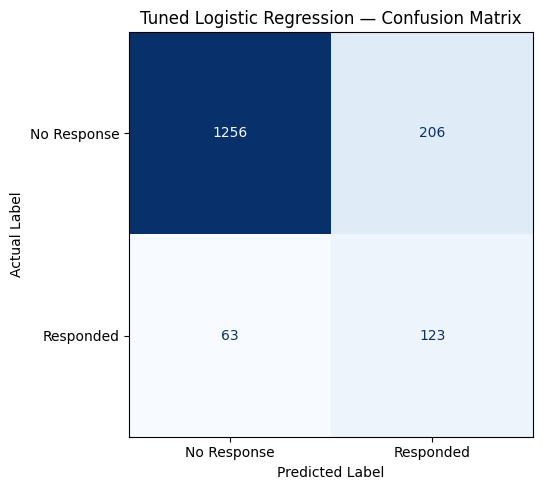


Tuned LightGBM — Evaluation

Classification Report:
              precision    recall  f1-score   support

 No Response       0.95      0.88      0.91      1462
   Responded       0.40      0.64      0.49       186

    accuracy                           0.85      1648
   macro avg       0.67      0.76      0.70      1648
weighted avg       0.89      0.85      0.86      1648



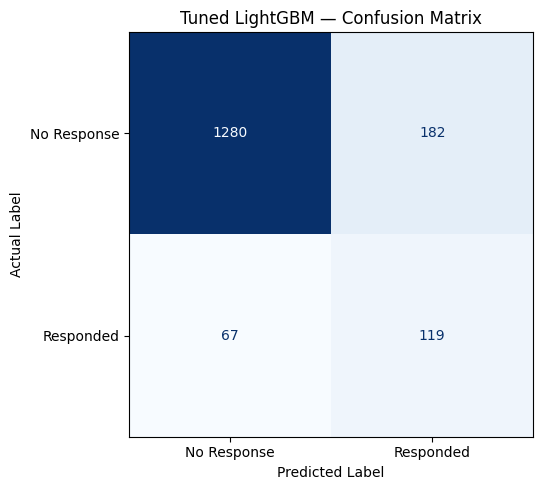

In [192]:
lr_tuned_metrics = evaluate_model(
    "Tuned Logistic Regression",
    lr_grid.best_estimator_,
    X_val,
    y_val
)

lgb_tuned_metrics = evaluate_model(
    "Tuned LightGBM",
    lgb_random_search.best_estimator_,
    X_val_lgb,
    y_val
)

We choose LightGBM as final canidate based on its validation performance. Among the tuned models, it achieved the higher F1-score, ccuract  and precision for the positive class than Logisitic Regresion.

The confusion matrix shows that LightGBM correctly identified 119 of the 186 actual responders while producing 182 false-positive predictions. Logistic Regression identified four additional responders but generated 24 more false positives. This suggests that LightGBM offers a slightly better balance between identifying potential responders and limiting unsuccessful marketing contacts.

LightGBM was also chosen for its ability to model nonlinear relationships and feature interactions and its support for native categorical features. Since the dataset has an imbalanced target, model selection considered precision, recall and F1-score rather than relying on accuracy alone.

Therefore, LightGBM is selected as the final model candidate for predicting customer responses to the marketing campaign. Its performance could be further improved by evaluating the prediction threshold against the insurance company's marketing costs and campaign objectives.

## 9. Final Model 

In [194]:
# Separate features and target
X_full = train_df.drop(columns=["responded"]).copy()
y_full = train_df["responded"].map({"no": 0, "yes": 1})

# Preserve test IDs
test_ids = test_df["id"].copy()

# Remove identifier and any non-feature columns from test data
X_test = test_df.drop(
    columns=["id", "responded", "profit"],
    errors="ignore"
).copy()
X_test = X_test.reindex(columns=X_full.columns)

print("Full training data:", X_full.shape)
print("Test data:", X_test.shape)

Full training data: (8238, 21)
Test data: (32950, 21)


In [195]:
X_full = engineer_features(X_full)
X_test = engineer_features(X_test)

In [196]:
#Prepare LightGBM categorical features
categorical_cols_final = X_full.select_dtypes(
    include=["object", "category", "string"]
).columns.tolist()


In [197]:
X_full_lgb = X_full.copy()
X_test_lgb = X_test.copy()

In [198]:
for col in categorical_cols_final:
    train_values = X_full_lgb[col].astype("string").fillna("Missing")
    test_values = X_test_lgb[col].astype("string").fillna("Missing")

    categories = train_values.unique().tolist()

    if "Missing" not in categories:
        categories.append("Missing")

    X_full_lgb[col] = pd.Categorical(
        train_values, categories=categories
    )

    X_test_lgb[col] = pd.Categorical(
        test_values, categories=categories
    )

In [199]:
final_lgb_model = lgb.LGBMClassifier(
    **lgb_random_search.best_params_,
    is_unbalance=True,
    random_state=42,
    verbosity=-1,
    n_jobs=-1
)

final_lgb_model.fit(
    X_full_lgb,
    y_full,
    categorical_feature=categorical_cols_final
)

LGBMClassifier(colsample_bytree=0.7043574493366855, is_unbalance=True,
               learning_rate=0.010423163159250268, max_depth=8,
               min_child_samples=67, n_estimators=295, n_jobs=-1, num_leaves=15,
               random_state=42, reg_alpha=0.04976078718408742,
               reg_lambda=0.26291710827226256, verbosity=-1)

In [200]:
test_pred = final_lgb_model.predict(X_test_lgb)

final_result = pd.DataFrame({
    "id": test_ids.to_numpy(),
    "responded": pd.Series(test_pred).map({
        0: "no",
        1: "yes"
    }).to_numpy()
})

final_result.to_csv("marketing_predictions.csv", index=False)

print(final_result.head())

print("\nPredicted response counts:")
print(final_result["responded"].value_counts())

print(f"\nSaved {len(final_result)} predictions.")

   id responded
0   1       yes
1   2       yes
2   3        no
3   4        no
4   5        no

Predicted response counts:
responded
no     26394
yes     6556
Name: count, dtype: int64

Saved 32950 predictions.
